# 03 - Face Mask Detection with MobileNetV2 (Transfer Learning)

Instead of learning features from scratch, reuse MobileNetV2 trained on ImageNet.

1. **Feature extraction:** freeze the pretrained base, train only the new classification head.
2. **Fine-tuning:** unfreeze the top layers of the base and continue with a *very small* learning rate.

The saved model contains `Rescaling(1/127.5, offset=-1)`, which is exactly what MobileNetV2 expects, so inference code feeds raw 0-255 RGB.

*Needs internet on first run to download the ImageNet weights.*

In [1]:
# Make the project importable and use the project root as working folder
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: e:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

from src.config import *

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow 2.15.1 | GPUs: []


## 1. Data

In [3]:
# Load images straight from the folders. Labels are one-hot, in MASK_CLASSES order.
def load_split(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        path,
        labels="inferred",
        label_mode="categorical",
        class_names=MASK_CLASSES,
        image_size=MASK_IMG_SIZE,
        batch_size=MASK_BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

train_ds = load_split(MASK_TRAIN_DIR, shuffle=True)
val_ds = load_split(MASK_VAL_DIR, shuffle=False)
test_ds = load_split(MASK_TEST_DIR, shuffle=False)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Class weights: rare classes get a bigger weight so the model does not ignore them
counts = np.array([len(list((MASK_TRAIN_DIR / c).glob("*"))) for c in MASK_CLASSES])
weights = counts.sum() / (len(counts) * counts)
class_weight = {i: float(w) for i, w in enumerate(weights)}
print("train images per class:", dict(zip(MASK_CLASSES, counts.tolist())))
print("class weights:", {MASK_CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

Found 1564 files belonging to 3 classes.
Found 350 files belonging to 3 classes.
Found 338 files belonging to 3 classes.
train images per class: {'mask_weared_incorrect': 56, 'with_mask': 1288, 'without_mask': 220}
class weights: {'mask_weared_incorrect': 9.31, 'with_mask': 0.4, 'without_mask': 2.37}


In [4]:
def plot_history(histories, title):
    acc = sum([h.history["accuracy"] for h in histories], [])
    val_acc = sum([h.history["val_accuracy"] for h in histories], [])
    loss = sum([h.history["loss"] for h in histories], [])
    val_loss = sum([h.history["val_loss"] for h in histories], [])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(acc, label="train"); axes[0].plot(val_acc, label="val"); axes[0].set_title(title + " - accuracy"); axes[0].legend()
    axes[1].plot(loss, label="train"); axes[1].plot(val_loss, label="val"); axes[1].set_title(title + " - loss"); axes[1].legend()
    plt.tight_layout(); plt.show()


def evaluate_model(model, ds, show=True):
    # ds must NOT be shuffled, so predictions line up with labels
    y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in ds])
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    if show:
        labels = list(range(len(MASK_CLASSES)))
        print(classification_report(y_true, y_pred, labels=labels, target_names=MASK_CLASSES, digits=3, zero_division=0))
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=labels),
                               display_labels=MASK_CLASSES).plot(cmap="Blues", xticks_rotation=25)
        plt.show()
    return y_true, y_pred

## 2. Model (frozen base + new head)

In [5]:
def build_mobilenet():
    base = keras.applications.MobileNetV2(
        input_shape=(*MASK_IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input(shape=(*MASK_IMG_SIZE, 3))

    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0)(x)   # MobileNetV2 wants [-1, 1]
    x = base(x, training=False)                                # keeps BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(MASK_CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mask_mobilenetv2"), base


model, base = build_mobilenet()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("Trainable weights (phase 1):", len(model.trainable_weights))



9406464/9406464 [==============================] - 1s 0us/step
Trainable weights (phase 1): 2


## 3. Phase 1 - train the head only

In [6]:
early = lambda: keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

h1 = model.fit(train_ds, validation_data=val_ds, epochs=15,
               class_weight=class_weight, callbacks=[early()])

Epoch 1/15


49/49 [==============================] - 29s 483ms/step - loss: 0.9811 - accuracy: 0.5614 - val_loss: 0.5421 - val_accuracy: 0.7771
Epoch 2/15
49/49 [==============================] - 25s 512ms/step - loss: 0.6660 - accuracy: 0.7059 - val_loss: 0.6085 - val_accuracy: 0.7514
Epoch 3/15
49/49 [==============================] - 24s 495ms/step - loss: 0.5206 - accuracy: 0.7807 - val_loss: 0.4991 - val_accuracy: 0.8086
Epoch 4/15
49/49 [==============================] - 26s 527ms/step - loss: 0.4387 - accuracy: 0.8043 - val_loss: 0.3972 - val_accuracy: 0.8429
Epoch 5/15
49/49 [==============================] - 25s 514ms/step - loss: 0.4077 - accuracy: 0.8318 - val_loss: 0.4551 - val_accuracy: 0.8057
Epoch 6/15
49/49 [==============================] - 25s 512ms/step - loss: 0.4273 - accuracy: 0.7928 - val_loss: 0.5054 - val_accuracy: 0.7886
Epoch 7/15
49/49 [==============================] - 26s 525ms/step - loss: 0.3848 - accuracy: 0.8382 - val_loss: 0.3353 - val_accuracy: 0.86

## 4. Phase 2 - fine-tune the last layers
A tiny learning rate (1e-5) protects the pretrained weights. The model **must be re-compiled** after changing `trainable`.

Trainable weights (phase 2): 34
Epoch 1/15
49/49 [==============================] - 41s 645ms/step - loss: 0.3994 - accuracy: 0.8453 - val_loss: 0.4284 - val_accuracy: 0.8114
Epoch 2/15
49/49 [==============================] - 30s 608ms/step - loss: 0.2973 - accuracy: 0.8811 - val_loss: 0.3399 - val_accuracy: 0.8686
Epoch 3/15
49/49 [==============================] - 28s 576ms/step - loss: 0.2895 - accuracy: 0.8728 - val_loss: 0.3522 - val_accuracy: 0.8714
Epoch 4/15
49/49 [==============================] - 24s 495ms/step - loss: 0.2543 - accuracy: 0.8862 - val_loss: 0.4437 - val_accuracy: 0.8229
Epoch 5/15
49/49 [==============================] - 28s 567ms/step - loss: 0.2569 - accuracy: 0.8804 - val_loss: 0.3326 - val_accuracy: 0.8714
Epoch 6/15
49/49 [==============================] - 30s 622ms/step - loss: 0.2427 - accuracy: 0.8951 - val_loss: 0.3492 - val_accuracy: 0.8600
Epoch 7/15
49/49 [==============================] - 29s 589ms/step - loss: 0.2501 - accuracy: 0.8887 - val_los

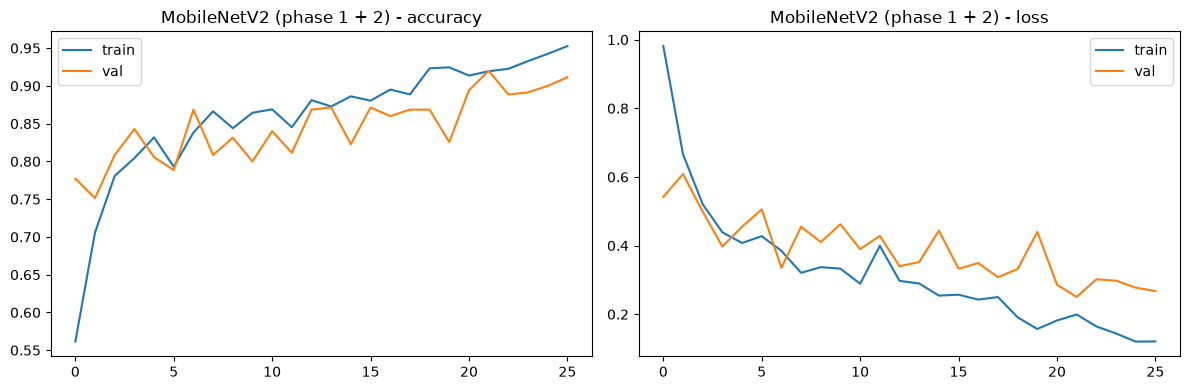

In [7]:
FINE_TUNE_LAYERS = 30

base.trainable = True
for layer in base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
print("Trainable weights (phase 2):", len(model.trainable_weights))

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h2 = model.fit(train_ds, validation_data=val_ds, epochs=15,
               class_weight=class_weight, callbacks=[early()])
plot_history([h1, h2], "MobileNetV2 (phase 1 + 2)")

## 5. Evaluate and compare with the scratch CNN

                       precision    recall  f1-score   support

mask_weared_incorrect      0.438     0.538     0.483        13
            with_mask      0.982     0.940     0.961       285
         without_mask      0.735     0.900     0.809        40

             accuracy                          0.920       338
            macro avg      0.718     0.793     0.751       338
         weighted avg      0.932     0.920     0.924       338



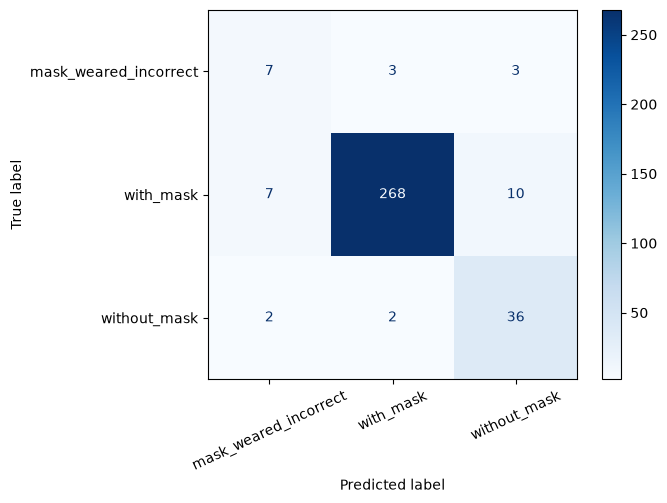

MobileNetV2  accuracy: 0.9201 | macro F1: 0.7508
Scratch CNN  accuracy: 0.0888 | macro F1: 0.0966


In [8]:
y_true, y_pred = evaluate_model(model, test_ds)
acc_mn = accuracy_score(y_true, y_pred)
f1_mn = f1_score(y_true, y_pred, average="macro")
print("MobileNetV2  accuracy:", round(acc_mn, 4), "| macro F1:", round(f1_mn, 4))

if MASK_CNN_PATH.exists():
    cnn = keras.models.load_model(MASK_CNN_PATH, compile=False)
    yt, yp = evaluate_model(cnn, test_ds, show=False)
    print("Scratch CNN  accuracy:", round(accuracy_score(yt, yp), 4),
          "| macro F1:", round(f1_score(yt, yp, average="macro"), 4))

## 6. Save and test through the project's inference code

In [9]:
model.save(MASK_MOBILENET_PATH)
print("Saved:", MASK_MOBILENET_PATH)

# src.mask_detection prefers this model automatically when it exists
from src.mask_detection import detect_and_classify, summarize_detections

for cls in MASK_CLASSES:
    path = next((MASK_TEST_DIR / cls).glob("*.jpg"))
    dets = detect_and_classify(cv2.imread(str(path)))
    print(f"true={cls:22s} predicted={dets[0]['label']:22s} confidence={dets[0]['confidence']:.2f}")
print(summarize_detections(dets))

Saved: E:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project\models\mask_mobilenetv2.keras
true=mask_weared_incorrect  predicted=with_mask              confidence=0.91
true=with_mask              predicted=with_mask              confidence=1.00
true=without_mask           predicted=without_mask           confidence=1.00
{'people_count': 1, 'mask_issue_count': 1, 'counts': {'mask_weared_incorrect': 0, 'with_mask': 0, 'without_mask': 1}}


**Done:** `models/mask_mobilenetv2.keras` is saved and will be used by the API. Next: notebook 04.